# 16 · Malha existente: o EAR calibrado acerta onde houve descarrilamento?

> **Regra da disciplina (aula 3):** especificação FOCUS → código gerado pelo assistente → executar → *gate* contra uma resposta já conhecida → aceitar.
> **Quando o gate falha, a restrição que faltou entra em `U`. O código não é remendado.**
>
> Cada passo abaixo tem três partes: a especificação FOCUS enviada ao assistente, o gate declarado **antes** do código (com a fonte da resposta conhecida e da tolerância) e o código que voltou, executado e gateado. O registro de uso de IA é exportado ao final (`registro_uso_ia.csv`).

**Pergunta fixada pelo autor (16/11).** O estudo é sobre a malha existente. A nota de cada quilômetro usa **somente atributos da via** (critérios do EAR e atributos declarados), como se o trecho fosse novo: o histórico de acidentes do quilômetro **não entra** como atributo. Os acidentes reais servem para duas coisas, em momentos separados: calibrar os pesos em um período e **conferir o acerto** em outro período.

**Desenho (declarado antes dos resultados).**

1. Blocos de cinco anos (2011 a 2015, 2016 a 2020, 2021 a 2025): calibrar em um bloco e conferir em cada um dos outros, para frente e para trás (seis pares).
2. Ano a ano: calibrar com todos os anos anteriores e conferir no ano seguinte (para frente); calibrar com todos os anos posteriores e conferir no ano anterior (para trás).
3. Em cada caso, duas conferências: (a) nos mesmos quilômetros, em outro período; (b) em quilômetros que ficaram fora da calibração (trechos inteiros sorteados em cinco grupos), em outro período. A conferência (b) é a mais exigente: nem o local nem o período foram vistos.

**Métodos sob o mesmo protocolo.** Regra do EAR por faixas (sem calibração); critérios do EAR em medida contínua (logística); critérios mais atributos declarados da via (logística, o modelo do trabalho); os mesmos atributos com gradient boosting. Hiperparâmetros fixos, iguais aos dos notebooks 11 e 14.

**Leitura da AUC como acerto.** Sorteando um quilômetro que teve descarrilamento no período conferido e um que não teve, a AUC é a fração das vezes em que o modelo deu nota maior ao que teve. Vale 0,50 para o acaso e 1,00 para o acerto total.

**Gates.** 2.681 descarrilamentos por via; os três blocos somam 2.681; períodos de calibração e de conferência disjuntos; teste de vazamento com rótulos embaralhados (média de 20 embaralhamentos) entre 0,45 e 0,55.

In [1]:
# === Setup: caminhos, bibliotecas e as três ferramentas (gate, gate_between, log_ia) ===
import os, sys, json, re, unicodedata, datetime as dt
import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if os.environ.get("ET261400_BASE"):
    BASE = os.environ["ET261400_BASE"]                # definido pelo notebook 00 (execução em lote) ou pela execução local
elif IN_COLAB and os.path.exists("/content/ET261400/data"):
    BASE = "/content/ET261400"                        # pacote já descompactado na sessão do Colab
elif IN_COLAB and os.path.exists("/content/et261400_colab.zip"):
    import zipfile
    zipfile.ZipFile("/content/et261400_colab.zip").extractall("/content/ET261400")   # pacote enviado pelo painel de arquivos
    BASE = "/content/ET261400"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    BASE = "/content/drive/MyDrive/ET261400"          # pasta do projeto no Drive (ajustar se for outra)
else:
    BASE = os.environ.get("ET261400_BASE", os.path.abspath(".."))   # execução local: raiz do repositório
RAW, PROC = f"{BASE}/data/raw", f"{BASE}/data/processed"
FIG, TAB = f"{BASE}/results/figures", f"{BASE}/results/tables"
for d in (PROC, FIG, TAB):
    os.makedirs(d, exist_ok=True)
print("BASE =", BASE)

_GATES = []          # todo gate executado fica registrado aqui
_LOG_IA = []         # registro de uso de IA: passo, ferramenta, especificação, resultado

def gate(name, got, expected, tol=0.0, source=""):
    """Compara um número calculado com um número que já se tinha antes do código.
    tol vem da fonte (meio passo de arredondamento, faixa publicada), nunca é alargada até passar."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = abs(got - expected) <= tol
    _GATES.append(dict(gate=name, got=got, expected=expected, tol=tol, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, esperado {expected} (tol +/-{tol}) {('| ' + source) if source else ''}")
    return ok

def gate_between(name, got, low, high, source=""):
    """O mesmo, quando a fonte publica uma faixa e não um número."""
    if got is None:
        print(f"[ -- ] {name}: nada calculado ainda"); return False
    ok = low <= got <= high
    _GATES.append(dict(gate=name, got=got, expected=f"[{low}, {high}]", tol=None, ok=ok, source=source))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: obtido {got}, faixa [{low}, {high}] {('| ' + source) if source else ''}")
    return ok

def log_ia(passo, ferramenta, especificacao, resultado, verificacao):
    """Registro de uso de IA exigido pela disciplina: o que foi pedido, a que ferramenta, o que voltou e como foi verificado."""
    _LOG_IA.append(dict(data=dt.date.today().isoformat(), passo=passo, ferramenta=ferramenta,
                        especificacao=especificacao.strip(), resultado=resultado, verificacao=verificacao))

def exportar_registros(prefixo):
    pd.DataFrame(_GATES).to_csv(f"{TAB}/{prefixo}_gates.csv", index=False)
    pd.DataFrame(_LOG_IA).to_csv(f"{TAB}/{prefixo}_registro_uso_ia.csv", index=False)
    n_ok = sum(g["ok"] for g in _GATES)
    print(f"gates: {n_ok}/{len(_GATES)} PASS | registros de IA: {len(_LOG_IA)} | exportados em {TAB}")

def norm_txt(s):
    """Maiúsculas sem acento, espaços simples: chave de junção para nomes de pátios e estações."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper().strip()


BASE = /home/claude


In [2]:
import warnings; warnings.filterwarnings("ignore")
from scipy.stats import rankdata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
SEED = 42
C0 = pd.read_csv(f"{PROC}/11_celulas_1km.csv")
C = C0[~C0["sentido"].astype(str).str.contains("Interromp")].sort_values(["ferrovia", "linha", "km_a"]).reset_index(drop=True); gate("células em operação", len(C), 20936, source="notebook 11")
E = pd.read_csv(f"{PROC}/11_eventos_celulas.csv"); E = E[E["cel_id"].isin(C["cel_id"])].copy(); E["ano"] = E["ano"].astype(int); EV = E[E["via"]]
gate("descarrilamentos por via nas células", len(EV), 2681, source="notebook 11")
idx = pd.Series(np.arange(len(C)), index=C["cel_id"])
def contagem(a0, a1):
    v = np.zeros(len(C)); s = EV[(EV["ano"] >= a0) & (EV["ano"] <= a1)].groupby("cel_id").size(); v[idx[s.index].values] = s.values; return v
BLOCOS = [(2011, 2015), (2016, 2020), (2021, 2025)]
gate("soma dos três blocos", int(sum(contagem(a, b).sum() for a, b in BLOCOS)), 2681, source="partição do período")
DIST = ["dmin_patio", "dmin_amv", "frac_zona_patio"] + [f"f16p{j}" for j in range(5)] + [f"f16a{j}" for j in range(5)]
CURV = ["rmin_geo"] + [f"fr_lt{l}" for l in (300, 400, 500, 600, 800)]
NUM = ["rampa_max_pct", "carga_eixo_t", "taxa_dorm", "gab_vert_m", "gab_horiz_m", "cap_vinc", "dias_op", "raio_min_m", "vma_carregado"]
CAT = ["dormente", "perfil_trilho", "fixacao", "sinalizacao", "controle_circ", "bitola", "sentido", "n_linhas"]
for c in NUM + DIST + CURV: C[c] = pd.to_numeric(C[c], errors="coerce")
for c in CAT: C[c] = C[c].astype(str).str.strip().replace({"nan": "NA", "": "NA"})
def design(df, num, cat):
    X = df[num].copy(); med = X.median().fillna(0.0)
    for c in num: X[c + "_na"] = X[c].isna().astype(float); X[c] = X[c].fillna(med[c])
    return (pd.concat([X, pd.get_dummies(df[cat], dtype=float)], axis=1) if cat else X).values
X_ear = design(C, DIST + CURV, []); X_full = design(C, DIST + CURV + NUM, CAT)
LN = C["len_km"].values; fer = np.asarray(C["ferrovia"], dtype=object); SEGC = pd.factorize(C["seg_id"].astype(str))[0]; NSEG = SEGC.max() + 1
def cls16(d): return np.select([d <= 300, d <= 600, d <= 1200, d <= 1800], [4, 3, 2, 1], 0)
def rcls16(r_): return np.select([r_ < 500, r_ < 1200, r_ < 2300], [3, 2, 1], 0)
B2 = (0.5 * cls16(C["dmin_patio"].fillna(1e9)) / 4 + 0.5 * rcls16(C["rmin_geo"].fillna(1e6)) / 3).astype(float)
def auc(yy, s, m=None):
    if m is not None: yy, s = yy[m], s[m]
    n1 = yy.sum(); n0_ = len(yy) - n1; return float((rankdata(s)[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0_)) if n1 >= 5 and n0_ >= 5 else np.nan
def auc_dentro(s, yy):
    a, w = [], []
    for f in np.unique(fer):
        i = fer == f
        if yy[i].sum() >= 5 and yy[i].sum() < i.sum(): a.append(auc(yy[i], s[i])); w.append(yy[i].sum())
    return float(np.average(a, weights=w)) if a else np.nan
def captura(s, evv, p=0.20):
    o = np.lexsort((np.random.default_rng(SEED).random(len(s)), -s)); cum = np.cumsum(LN[o]) / LN.sum(); return float(evv[o][cum <= p].sum() / evv.sum())
def lr(Xtr, ytr, Xte):
    st = StandardScaler().fit(Xtr); return LogisticRegression(C=0.5, max_iter=3000).fit(st.transform(Xtr), ytr).predict_proba(st.transform(Xte))[:, 1]
def gbm(Xtr, ytr, Xte): return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, early_stopping=False, random_state=SEED).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
MET = {"Critérios do EAR em medida contínua": (X_ear, lr), "EAR calibrado: critérios + atributos da via (logística)": (X_full, lr), "Critérios + atributos da via (gradient boosting)": (X_full, gbm)}
def avaliar(cal, conf, tag, sorteios=1, metodos=MET, embaralhar=None):
    """cal e conf: (ano inicial, ano final). Devolve linhas para as duas conferências: mesmos km e km fora da calibração."""
    assert cal[1] < conf[0] or conf[1] < cal[0], "períodos sobrepostos"
    ycal = (contagem(*cal) > 0).astype(int); cconf = contagem(*conf); yconf = (cconf > 0).astype(int); novo = ycal == 0; L = []
    if embaralhar is not None: ycal = np.random.default_rng(1000 + embaralhar).permutation(ycal)
    base = dict(cenario=tag, calibra=f"{cal[0]} a {cal[1]}", confere=f"{conf[0]} a {conf[1]}", sentido="para frente" if cal[1] < conf[0] else "para trás", km_com_acidente_no_conferido=int(yconf.sum()), deles_sem_acidente_na_calibracao=int(yconf[novo].sum()))
    def linha(nome, conferencia, s): return dict(base, metodo=nome, conferencia=conferencia, auc=auc(yconf, s), auc_dentro=auc_dentro(s, yconf), captura20=captura(s, cconf), auc_km_sem_acidente_na_calibracao=auc(yconf, s, novo))
    for conferencia in ("mesmos km, outro período", "km fora da calibração, outro período"): L.append(linha("Regra do EAR por faixas (sem calibração)", conferencia, B2))
    for nome, (X, f) in metodos.items():
        L.append(linha(nome, "mesmos km, outro período", f(X, ycal, X)))
        for r in range(sorteios):
            fold = np.random.default_rng(SEED + r).permutation(NSEG)[SEGC] % 5; s = np.zeros(len(C))
            for k in range(5): te = fold == k; s[te] = f(X[~te], ycal[~te], X[te])
            L.append(dict(linha(nome, "km fora da calibração, outro período", s), sorteio=r))
    return L
log_ia("16.1 dados e funções", "Claude", "FOCUS: só atributos da via; acidentes calibram em um período e conferem em outro; conferência em km fora da calibração por grupos de trecho", "avaliar(cal, conf)", "3 gates de contagem")

[PASS] células em operação: obtido 20936, esperado 20936 (tol +/-0.0) | notebook 11
[PASS] descarrilamentos por via nas células: obtido 2681, esperado 2681 (tol +/-0.0) | notebook 11
[PASS] soma dos três blocos: obtido 2681, esperado 2681 (tol +/-0.0) | partição do período


In [3]:
# 1. Blocos de cinco anos: seis pares, para frente e para trás
L = []
for i, a in enumerate(BLOCOS):
    for j, b in enumerate(BLOCOS):
        if i != j: L += avaliar(a, b, "blocos de 5 anos", sorteios=3); print(a, "->", b, "ok", flush=True)
R1 = pd.DataFrame(L)
gate("pares de blocos avaliados", int(R1[["calibra", "confere"]].drop_duplicates().shape[0]), 6, source="desenho")
LRM = {"EAR calibrado: critérios + atributos da via (logística)": MET["EAR calibrado: critérios + atributos da via (logística)"]}
vz = pd.concat([pd.DataFrame(avaliar(BLOCOS[0], BLOCOS[2], "vazamento", metodos=LRM, embaralhar=k)) for k in range(20)])
vzm = vz[(vz.metodo.str.startswith("EAR calibrado")) & (vz.conferencia.str.startswith("km fora"))]["auc"]; print("vazamento: média", round(vzm.mean(), 3), "| mínimo", round(vzm.min(), 3), "| máximo", round(vzm.max(), 3))
# Restrição acrescentada à especificação em 16/11 (gate loop): na primeira execução o gate usou um único embaralhamento e falhou (0,447, faixa 0,45 a 0,55).
# Com rótulos embaralhados o ajuste devolve uma direção aleatória num espaço de atributos com forte estrutura espacial (a malha), que se correlaciona com a resposta para cima ou para baixo por acaso.
# O teste correto é a média de vários embaralhamentos; a tolerância não mudou.
gate_between("teste de vazamento (média de 20 embaralhamentos), AUC em km fora da calibração", float(vzm.mean()), 0.45, 0.55, source="acaso")
COLS = ["auc", "auc_dentro", "captura20", "auc_km_sem_acidente_na_calibracao"]
r1 = R1.groupby(["conferencia", "metodo"], sort=False)[COLS].agg(["mean", "min", "max"]).round(3); display(r1)
display(R1[R1.metodo.str.startswith("EAR calibrado")].groupby(["conferencia", "calibra", "confere", "sentido"], sort=False)[["auc", "auc_dentro", "captura20", "km_com_acidente_no_conferido", "deles_sem_acidente_na_calibracao"]].mean().round(3))
log_ia("16.2 blocos de 5 anos", "Claude", "FOCUS: seis pares; três sorteios de grupos de trecho", "R1", "gate de pares; teste de vazamento")

(2011, 2015) -> (2016, 2020) ok


(2011, 2015) -> (2021, 2025) ok


(2016, 2020) -> (2011, 2015) ok


(2016, 2020) -> (2021, 2025) ok


(2021, 2025) -> (2011, 2015) ok


(2021, 2025) -> (2016, 2020) ok


[PASS] pares de blocos avaliados: obtido 6, esperado 6 (tol +/-0.0) | desenho


vazamento: média 0.488 | mínimo 0.409 | máximo 0.621
[PASS] teste de vazamento (média de 20 embaralhamentos), AUC em km fora da calibração: obtido 0.4876121228608512, faixa [0.45, 0.55] | acaso


auc  \
                                                                                          mean   
conferencia                          metodo                                                      
mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.584   
km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.584   
mesmos km, outro período             Critérios do EAR em medida contínua                 0.630   
km fora da calibração, outro período Critérios do EAR em medida contínua                 0.625   
mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.738   
km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.731   
mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.755   
km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.729   

                                                                                                \
                                                                                           min   
conferencia                          metodo                                                      
mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.567   
km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.567   
mesmos km, outro período             Critérios do EAR em medida contínua                 0.609   
km fora da calibração, outro período Critérios do EAR em medida contínua                 0.598   
mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.700   
km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.695   
mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.704   
km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.679   

                                                                                                \
                                                                                           max   
conferencia                          metodo                                                      
mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.596   
km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.596   
mesmos km, outro período             Critérios do EAR em medida contínua                 0.660   
km fora da calibração, outro período Critérios do EAR em medida contínua                 0.656   
mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.801   
km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.788   
mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.823   
km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.800   

                                                                                        auc_dentro  \
                                                                                              mean   
conferencia                          metodo                                                          
mesmos km, outro período             Regra do EAR por faixas (sem calibração)                0.583   
km fora da calibração, outro período Regra do EAR por faixas (sem calibração)                0.583   
mesmos km, outro período             Critérios do EAR em medida contínua                     0.643   
km fora da calibração, outro período Critérios do EAR em medida contínua                     0.642   
mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...      0.657   
km fora da calibração, outro período E

,,,,auc,auc_dentro,captura20,km_com_acidente_no_conferido,deles_sem_acidente_na_calibracao
conferencia,calibra,confere,sentido,,,,,
"mesmos km, outro período",2011 a 2015,2016 a 2020,para frente,0.720,0.662,0.472,760.0,641.0
"km fora da calibração, outro período",2011 a 2015,2016 a 2020,para frente,0.718,0.650,0.456,760.0,641.0
"mesmos km, outro período",2011 a 2015,2021 a 2025,para frente,0.742,0.640,0.519,482.0,397.0
"km fora da calibração, outro período",2011 a 2015,2021 a 2025,para frente,0.740,0.630,0.519,482.0,397.0
"mesmos km, outro período",2016 a 2020,2011 a 2015,para trás,0.731,0.663,0.509,1141.0,1022.0
"km fora da calibração, outro período",2016 a 2020,2011 a 2015,para trás,0.722,0.649,0.493,1141.0,1022.0
"mesmos km, outro período",2016 a 2020,2021 a 2025,para frente,0.801,0.690,0.631,482.0,412.0
"km fora da calibração, outro período",2016 a 2020,2021 a 2025,para frente,0.786,0.670,0.590,482.0,412.0
"mesmos km, outro período",2021 a 2025,2011 a 2015,para trás,0.700,0.625,0.416,1141.0,1056.0


In [4]:
# 2. Ano a ano: para frente (anos anteriores -> ano seguinte) e para trás (anos posteriores -> ano anterior)
L = []
for T in range(2016, 2026): L += avaliar((2011, T - 1), (T, T), "ano a ano"); print("frente", T, flush=True)
for T in range(2011, 2021): L += avaliar((T + 1, 2025), (T, T), "ano a ano"); print("trás", T, flush=True)
R2 = pd.DataFrame(L); gate("conferências ano a ano", int(R2[["calibra", "confere"]].drop_duplicates().shape[0]), 20, source="desenho: 10 para frente e 10 para trás")
r2 = R2.groupby(["conferencia", "sentido", "metodo"], sort=False)[COLS].agg(["mean", "min", "max"]).round(3); display(r2)
display(R2[R2.metodo.str.startswith("EAR calibrado")].pivot_table(index=["sentido", "confere"], columns="conferencia", values="auc", sort=False).round(3))
R = pd.concat([R1, R2], ignore_index=True); R.to_csv(f"{TAB}/16_acerto_por_conferencia.csv", index=False)
res = R.groupby(["cenario", "conferencia", "metodo"], sort=False)[COLS].agg(["mean", "min", "max"]).round(3); res.to_csv(f"{TAB}/16_acerto_resumo.csv"); display(res)
log_ia("16.3 ano a ano", "Claude", "FOCUS: 20 conferências anuais, duas direções", "16_acerto_*.csv", "gate de número de conferências")

frente 2016


frente 2017


frente 2018


frente 2019


frente 2020


frente 2021


... (14 outputs left out)

[PASS] conferências ano a ano: obtido 20, esperado 20 (tol +/-0.0) | desenho: 10 para frente e 10 para trás


auc  \
                                                                                                      mean   
conferencia                          sentido     metodo                                                      
mesmos km, outro período             para frente Regra do EAR por faixas (sem calibração)            0.581   
km fora da calibração, outro período para frente Regra do EAR por faixas (sem calibração)            0.581   
mesmos km, outro período             para frente Critérios do EAR em medida contínua                 0.633   
km fora da calibração, outro período para frente Critérios do EAR em medida contínua                 0.625   
mesmos km, outro período             para frente EAR calibrado: critérios + atributos da via (lo...  0.755   
km fora da calibração, outro período para frente EAR calibrado: critérios + atributos da via (lo...  0.748   
mesmos km, outro período             para frente Critérios + atributos da via (gradient boosting)    0.788   
km fora da calibração, outro período para frente Critérios + atributos da via (gradient boosting)    0.749   
mesmos km, outro período             para trás   Regra do EAR por faixas (sem calibração)            0.592   
km fora da calibração, outro período para trás   Regra do EAR por faixas (sem calibração)            0.592   
mesmos km, outro período             para trás   Critérios do EAR em medida contínua                 0.645   
km fora da calibração, outro período para trás   Critérios do EAR em medida contínua                 0.637   
mesmos km, outro período             para trás   EAR calibrado: critérios + atributos da via (lo...  0.744   
km fora da calibração, outro período para trás   EAR calibrado: critérios + atributos da via (lo...  0.733   
mesmos km, outro período             para trás   Critérios + atributos da via (gradient boosting)    0.770   
km fora da calibração, outro período para trás   Critérios + atributos da via (gradient boosting)    0.742   

                                                                                                            \
                                                                                                       min   
conferencia                          sentido     metodo                                                      
mesmos km, outro período             para frente Regra do EAR por faixas (sem calibração)            0.559   
km fora da calibração, outro período para frente Regra do EAR por faixas (sem calibração)            0.559   
mesmos km, outro período             para frente Critérios do EAR em medida contínua                 0.586   
km fora da calibração, outro período para frente Critérios do EAR em medida contínua                 0.588   
mesmos km, outro período             para frente EAR calibrado: critérios + atributos da via (lo...  0.697   
km fora da calibração, outro período para frente EAR calibrado: critérios + atributos da via (lo...  0.698   
mesmos km, outro período             para frente Critérios + atributos da via (gradient boosting)    0.729   
km fora da calibração, outro período para frente Critérios + atributos da via (gradient boosting)    0.700   
mesmos km, outro período             para trás   Regra do EAR por faixas (sem calibração)            0.554   
km fora da calibração, outro período para trás   Regra do EAR por faixas (sem calibração)            0.554   
mesmos km, outro período             para trás   Critérios do EAR em medida contínua                 0.567   
km fora da calibração, outro período para trás   Critérios do EAR em medida contínua                 0.561   
mesmos km, outro período             para trás   EAR calibrado: critérios + atributos da via (lo...  0.707   
km fora da calibração, outro período para trás   EAR calibrado: critérios + atributos da via (lo...  0.696   
mesmos km, outro período             para trás   Critérios + atributos da via (gradient boosting)    0.731   
km fora da calibração, outro per

conferencia              mesmos km, outro período  \
sentido     confere                                 
para frente 2016 a 2016                     0.703   
            2017 a 2017                     0.751   
            2018 a 2018                     0.697   
            2019 a 2019                     0.732   
            2020 a 2020                     0.750   
            2021 a 2021                     0.755   
            2022 a 2022                     0.803   
            2023 a 2023                     0.800   
            2024 a 2024                     0.756   
            2025 a 2025                     0.807   
para trás   2016 a 2016                     0.762   
            2017 a 2017                     0.749   
            2018 a 2018                     0.720   
            2019 a 2019                     0.707   
            2020 a 2020                     0.768   
            2011 a 2011                     0.744   
            2012 a 2012                     0.745   
            2013 a 2013                     0.746   
            2014 a 2014                     0.766   
            2015 a 2015                     0.736   

conferencia              km fora da calibração, outro período  
sentido     confere                                            
para frente 2016 a 2016                                 0.703  
            2017 a 2017                                 0.744  
            2018 a 2018                                 0.698  
            2019 a 2019                                 0.726  
            2020 a 2020                                 0.745  
            2021 a 2021                                 0.742  
            2022 a 2022                                 0.786  
            2023 a 2023                                 0.790  
            2024 a 2024                                 0.750  
            2025 a 2025                                 0.800  
para trás   2016 a 2016                                 0.754  
            2017 a 2017                                 0.741  
            2018 a 2018                                 0.708  
            2019 a 2019                                 0.696  
            2020 a 2020                                 0.743  
            2011 a 2011                                 0.734  
            2012 a 2012                                 0.736  
            2013 a 2013                                 0.738  
            2014 a 2014                                 0.755  
            2015 a 2015                                 0.727

auc  \
                                                                                                           mean   
cenario          conferencia                          metodo                                                      
blocos de 5 anos mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.584   
                 km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.584   
                 mesmos km, outro período             Critérios do EAR em medida contínua                 0.630   
                 km fora da calibração, outro período Critérios do EAR em medida contínua                 0.625   
                 mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.738   
                 km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.731   
                 mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.755   
                 km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.729   
ano a ano        mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.587   
                 km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.587   
                 mesmos km, outro período             Critérios do EAR em medida contínua                 0.639   
                 km fora da calibração, outro período Critérios do EAR em medida contínua                 0.631   
                 mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.750   
                 km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.741   
                 mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.779   
                 km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.745   

                                                                                                                 \
                                                                                                            min   
cenario          conferencia                          metodo                                                      
blocos de 5 anos mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.567   
                 km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.567   
                 mesmos km, outro período             Critérios do EAR em medida contínua                 0.609   
                 km fora da calibração, outro período Critérios do EAR em medida contínua                 0.598   
                 mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.700   
                 km fora da calibração, outro período EAR calibrado: critérios + atributos da via (lo...  0.695   
                 mesmos km, outro período             Critérios + atributos da via (gradient boosting)    0.704   
                 km fora da calibração, outro período Critérios + atributos da via (gradient boosting)    0.679   
ano a ano        mesmos km, outro período             Regra do EAR por faixas (sem calibração)            0.554   
                 km fora da calibração, outro período Regra do EAR por faixas (sem calibração)            0.554   
                 mesmos km, outro período             Critérios do EAR em medida contínua                 0.567   
                 km fora da calibração, outro período Critérios do EAR em medida contínua                 0.561   
                 mesmos km, outro período             EAR calibrado: critérios + atributos da via (lo...  0.697   
                 km fora da calibração, outro período EAR calibrado: critérios + a

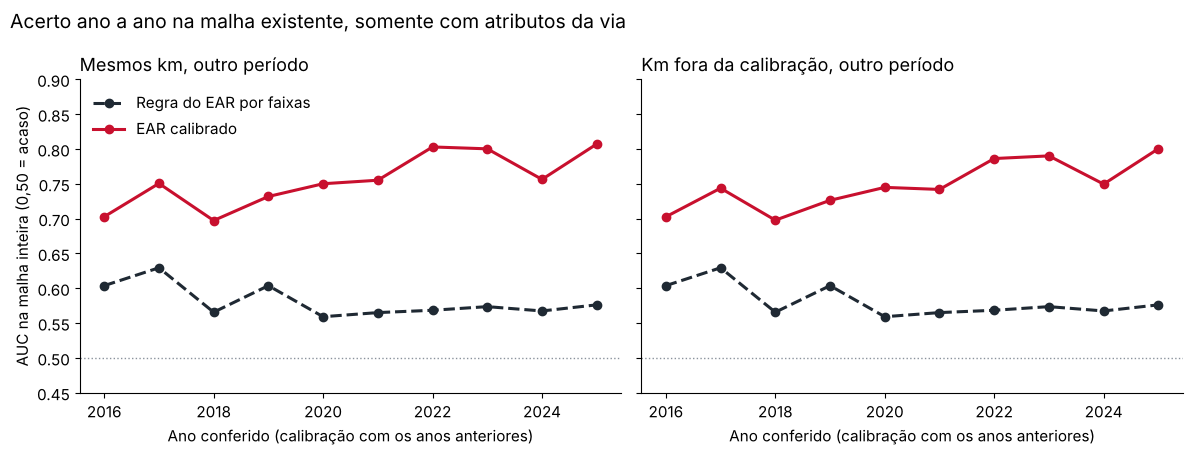

gates: 6/6 PASS | registros de IA: 3 | exportados em /home/claude/results/tables


In [5]:
# 3. Figura: acerto (AUC) em cada conferência, regra por faixas versus EAR calibrado
import matplotlib.pyplot as plt
INK, ACC, GR = "#1F2933", "#C8102E", "#8A929C"
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for a, conf, tit in [(ax[0], "mesmos km, outro período", "Mesmos km, outro período"), (ax[1], "km fora da calibração, outro período", "Km fora da calibração, outro período")]:
    d = R2[R2.conferencia == conf]; d = d[d.sentido == "para frente"]
    for nome, cor, ls in [("Regra do EAR por faixas (sem calibração)", INK, "--"), ("EAR calibrado: critérios + atributos da via (logística)", ACC, "-")]:
        g = d[d.metodo == nome].groupby("confere", sort=False)["auc"].mean(); a.plot([int(x[:4]) for x in g.index], g.values, ls, color=cor, lw=2.2, marker="o", label=nome.split(":")[0].replace(" (sem calibração)", ""))
    a.axhline(0.5, color=GR, lw=1, ls=":"); a.set_title(tit, fontsize=13, loc="left"); a.set_xlabel("Ano conferido (calibração com os anos anteriores)", fontsize=11); a.set_ylim(0.45, 0.9); a.tick_params(labelsize=11)
    for sp in ("top", "right"): a.spines[sp].set_visible(False)
ax[0].set_ylabel("AUC na malha inteira (0,50 = acaso)", fontsize=11); ax[0].legend(frameon=False, fontsize=11, loc="upper left")
fig.suptitle("Acerto ano a ano na malha existente, somente com atributos da via", fontsize=14, x=0.01, ha="left"); fig.tight_layout(); fig.savefig(f"{FIG}/16_acerto_ano_a_ano.png", dpi=200); plt.show()
exportar_registros("16")

---
## Limites

Os atributos da via são os da Declaração de Rede de 2025 em todos os períodos. Na conferência nos mesmos quilômetros, o padrão espacial dos acidentes persiste entre períodos e parte do acerto vem dessa persistência; por isso a conferência em quilômetros fora da calibração é reportada ao lado. O registro do RAAF mudou de arquivo em dezembro de 2020. Em anos isolados o número de quilômetros com descarrilamento é pequeno e a AUC oscila mais.

**Declaração de uso de IA (regra da disciplina, três partes).** Ferramentas: Claude (Anthropic), usado pelo autor como assistente de programação a partir das especificações FOCUS registradas neste notebook, e Gemini do Colab quando indicado. Parte do trabalho: geração do código de cada passo e revisão do texto das células. Responsável pelo conteúdo: o autor, que definiu o problema, as fontes, as especificações, os gates e a verificação, e executou o notebook do zero antes de reportar qualquer número.